In [1]:
import matplotlib.pyplot as plt
import seaborn as sns

print(df.head())
print(df.columns)
print(df.shape)

NameError: name 'df' is not defined

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("synthetic_job_market.csv")

In [3]:
print(df.head())
print(df.shape)
print(df.columns)


         job_role  experience_years  salary_lpa  skill_count company_size  \
0     ML Engineer               2.4       16.08            5      Startup   
1     ML Engineer              10.0       26.55            4      Startup   
2     ML Engineer               5.0       19.20            3      Startup   
3  Data Scientist               3.7       10.88            6     Mid-size   
4  Data Scientist               1.5       12.01            6      Startup   

   python_required  
0             True  
1             True  
2             True  
3            False  
4             True  
(200, 6)
Index(['job_role', 'experience_years', 'salary_lpa', 'skill_count',
       'company_size', 'python_required'],
      dtype='str')


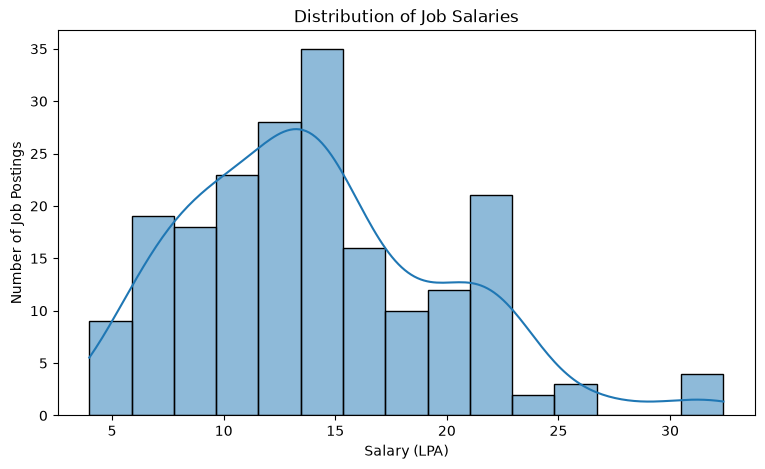

In [4]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="salary_lpa",
    bins=15,
    kde=True
)

plt.title("Distribution of Job Salaries")
plt.xlabel("Salary (LPA)")
plt.ylabel("Number of Job Postings")

plt.show()

In [5]:
print("Mean:", df["salary_lpa"].mean())
print("Median:", df["salary_lpa"].median())
print("Skewness:", df["salary_lpa"].skew())

Mean: 14.14975
Median: 13.57
Skewness: 0.6864323386103304


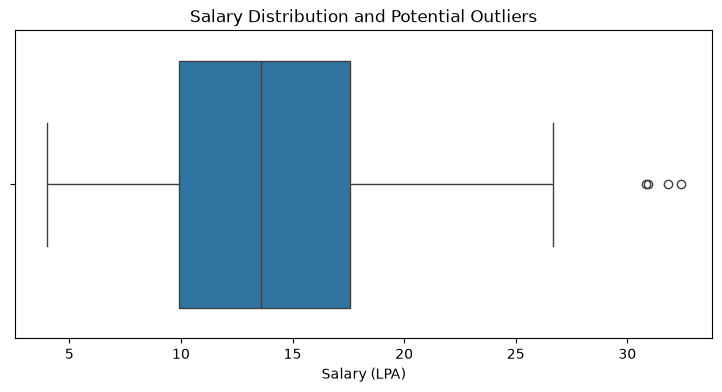

In [6]:
plt.figure(figsize=(9, 4))

sns.boxplot(data=df, x="salary_lpa")

plt.title("Salary Distribution and Potential Outliers")
plt.xlabel("Salary (LPA)")

plt.show()

In [7]:
Q1 = df["salary_lpa"].quantile(0.25)
Q3 = df["salary_lpa"].quantile(0.75)

IQR = Q3 - Q1

upper_bound = Q3 + 1.5 * IQR
lower_bound = Q1 - 1.5 * IQR

outliers = df[
    (df["salary_lpa"] < lower_bound) |
    (df["salary_lpa"] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Upper bound:", upper_bound)
print("Lower bound:", lower_bound)
print("Number of potential outliers:", len(outliers))
print(outliers[["job_role", "salary_lpa"]])

Q1: 9.905000000000001
Q3: 17.555
IQR: 7.649999999999999
Upper bound: 29.029999999999998
Lower bound: -1.5699999999999967
Number of potential outliers: 4
              job_role  salary_lpa
50      Data Scientist       30.93
69   Software Engineer       32.39
139  Software Engineer       30.82
154     Data Scientist       31.83


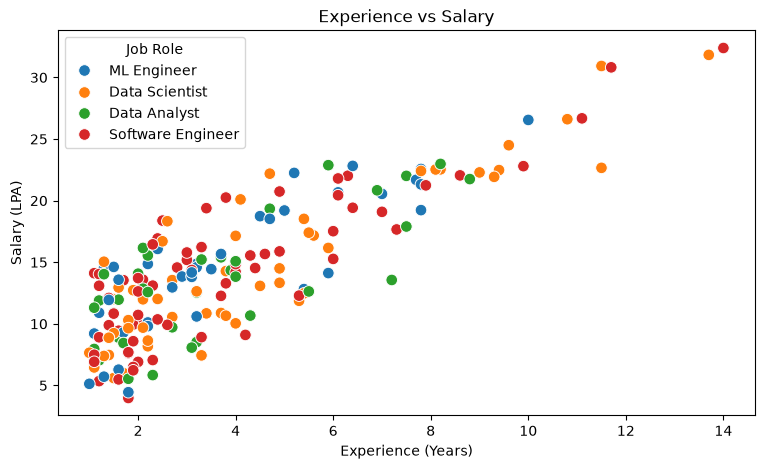

In [8]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="experience_years",
    y="salary_lpa",
    hue="job_role",
    s=70
)

plt.title("Experience vs Salary")
plt.xlabel("Experience (Years)")
plt.ylabel("Salary (LPA)")
plt.legend(title="Job Role")
plt.show()

In [9]:
correlation = df["experience_years"].corr(df["salary_lpa"])

print("Pearson Correlation:", correlation)

Pearson Correlation: 0.849013430746826


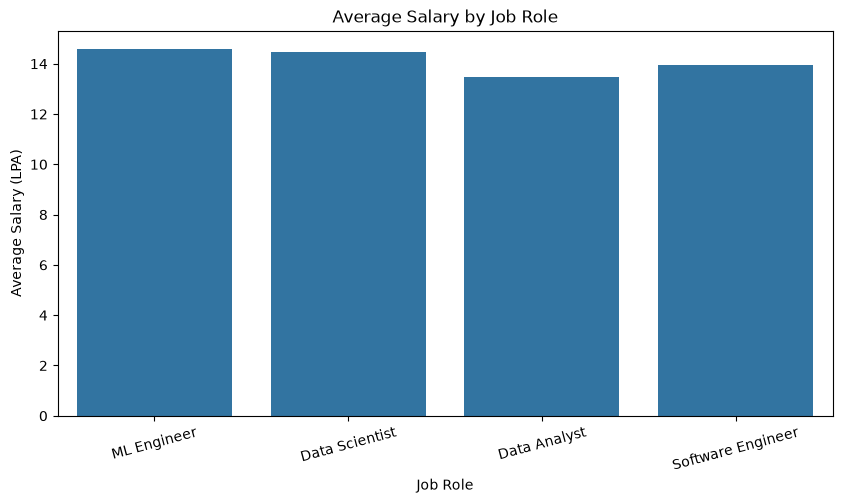

In [10]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=df,
    x="job_role",
    y="salary_lpa",
    errorbar=None
)

plt.title("Average Salary by Job Role")
plt.xlabel("Job Role")
plt.ylabel("Average Salary (LPA)")
plt.xticks(rotation=15)

plt.show()

# Day 10: Data Visualization Report

## 1. Salary Distribution
- Most salaries are concentrated around 10–15 LPA.
- The distribution is positively skewed.
- Mean: 14.15 LPA
- Median: 13.57 LPA

## 2. Outlier Analysis
- Potential outliers identified using IQR.
- Number of potential outliers: 4.
- Outliers should be investigated before removal.

## 3. Experience vs Salary
- Pearson correlation: 0.85.
- Strong positive linear association.
- Correlation does not establish causation.

## 4. Salary by Job Role
- Highest average: ML Engineer.
- Lowest average: Data Analyst.
- Differences require further investigation.

## 5. Conclusion
## 5. Conclusion

Through this visualization analysis, I observed that:

1. Most job salaries are concentrated between 10 and 15 LPA.
2. The salary distribution is positively skewed, with a few unusually high salary observations.
3. The boxplot identified 4 potential outliers using the IQR method. These values should be investigated rather than automatically removed.
4. Experience and salary have a strong positive linear association, with a Pearson correlation of 0.85. However, correlation does not establish causation.
5. ML Engineer has the highest average salary, while Data Analyst has the lowest average salary among the four job roles.

Overall, data visualization helped me understand salary distribution, identify potential outliers, explore relationships between variables, and compare job categories.

**Limitation:** This analysis uses a synthetic dataset of 200 job postings. Therefore, these findings are useful for statistical practice but cannot be treated as actual job-market insights.